In [54]:
import numpy as np
import hcipy as hp
import hcipy as hcipy
import matplotlib.pyplot as plt



In [55]:
# Telescope / instrument constants
pupil_diameter = 6.5            # m
effective_focal_length = 71.5   # m

# Available filters
filters = {
    '875': {'name': '875 nm', 'wavelength': 875e-9, 'bandwidth': 0.03},
    'z':     {'name': 'z band',  'wavelength': 908e-9, 'bandwidth': 0.14},
}


In [56]:
def make_pupil(diameter=pupil_diameter, n=256, supersample=10):
    """Magellan pupil (supersampled) on a physical pupil grid."""
    grid = hcipy.make_pupil_grid(n, diameter=diameter)
    pupil = hp.evaluate_supersampled(hcipy.make_magellan_aperture(), grid, supersample)
    return grid, pupil

def make_propagator(pupil_grid, reference_wavelength, diameter=pupil_diameter,
                    focal_length=effective_focal_length, q=4, num_airy=16):
    """Fraunhofer propagator to a focal grid referenced at reference_wavelength."""
    focal_grid = hcipy.make_focal_grid(q=q, num_airy=num_airy, pupil_diameter=diameter,
                                       focal_length=focal_length, reference_wavelength=reference_wavelength)
    return hcipy.FraunhoferPropagator(pupil_grid, focal_grid, focal_length=focal_length)

def monochromatic_psf(pupil, wavelength, propagator):
    """PSF intensity at a single wavelength."""
    return propagator.forward(hcipy.Wavefront(pupil, wavelength)).intensity

def broadband_psf(pupil, filt, propagator, n=11):
    """Incoherent sum of PSFs across the filter's band."""
    wlens = filt['wavelength'] * np.linspace(1 - filt['bandwidth'] / 2, 1 + filt['bandwidth'] / 2, n)
    total = 0
    for wlen in wlens:
        total += monochromatic_psf(pupil, wlen, propagator)
    return total

def plot_psf(psf, title=''):
    """Log-scaled imshow of a PSF intensity, in microns."""
    hcipy.imshow_field(np.log10(psf / psf.max()), vmin=-5, grid_units=1e-6)
    plt.colorbar()
    plt.xlabel(r'Focal plane distance [$\mu m$]')
    plt.ylabel(r'Focal plane distance [$\mu m$]')
    plt.title(title)
    plt.show()


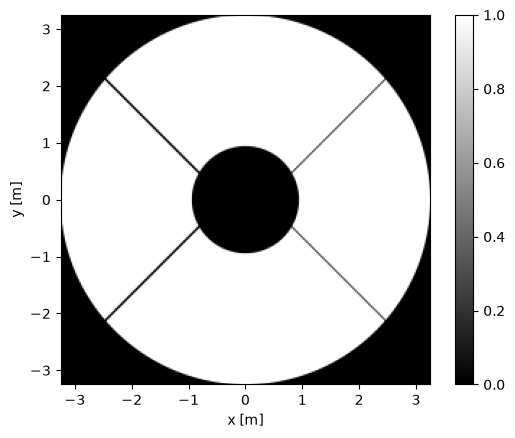

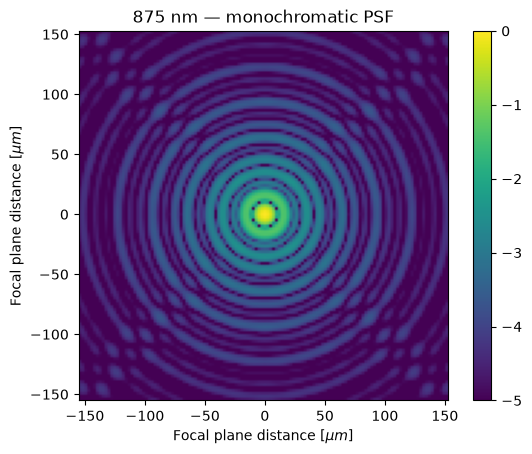

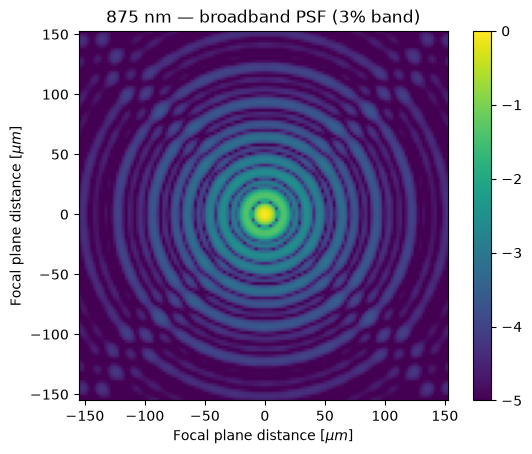

In [ ]:
# Pick filter: filters['875'] or filters['z']
filt = filters['875']

pupil_grid, pupil = make_pupil()

hcipy.imshow_field(pupil, cmap='gray')
plt.colorbar()
plt.xlabel('x [m]')
plt.ylabel('y [m]')
plt.show()

prop = make_propagator(pupil_grid, filt['wavelength'])

plot_psf(monochromatic_psf(pupil, filt['wavelength'], prop),
         title=filt['name'] + ' — monochromatic PSF')

plot_psf(broadband_psf(pupil, filt, prop),
         title=filt['name'] + ' — broadband PSF ({:.0f}% band)'.format(filt['bandwidth'] * 100))
